# Task 3 (Implement Both Using Libraries (scikit-learn))

We train `sklearn.linear_model.Perceptron` and `sklearn.linear_model.LogisticRegression` on **exactly the same prepared training and test data** from Task 1, with consistent `random_state=42`.
Then we plot **all four decision boundaries** (scratch Perceptron, scratch Logistic, sklearn Perceptron, sklearn Logistic) on the two chosen predictors (Glucose, BMI) and explain why the boundaries and coefficients differ.

## 0. Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Perceptron, LogisticRegression

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1. Load the Prepared Data from Task 1

Same loading logic as Task 2: use `prepared_diabetes_data.npz` if present, otherwise rebuild the identical pipeline (stratified 80/20 split, `random_state=42`, train-only median imputation and scaling).

In [2]:
if os.path.exists("prepared_diabetes_data.npz"):
    d = np.load("prepared_diabetes_data.npz", allow_pickle=True)
    X_train, X_test = d["X_train"], d["X_test"]
    y_train, y_test = d["y_train"], d["y_test"]
    FEATURES = [str(f) for f in d["features"]]
    print("Loaded prepared_diabetes_data.npz")
else:
    from sklearn.model_selection import train_test_split
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import StandardScaler

    COLS = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
            "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]
    if os.path.exists("diabetes.csv"):
        df = pd.read_csv("diabetes.csv")
    else:
        url = ("https://raw.githubusercontent.com/jbrownlee/Datasets/master/"
               "pima-indians-diabetes.data.csv")
        df = pd.read_csv(url, header=None, names=COLS)

    FEATURES = ["Glucose", "BMI"]
    df[["Glucose", "BMI"]] = df[["Glucose", "BMI"]].replace(0, np.nan)
    Xr, yr = df[FEATURES], df["Outcome"]
    Xtr, Xte, ytr, yte = train_test_split(Xr, yr, test_size=0.20, stratify=yr,
                                          random_state=RANDOM_STATE)
    imp = SimpleImputer(strategy="median").fit(Xtr)
    sc = StandardScaler().fit(imp.transform(Xtr))
    X_train = sc.transform(imp.transform(Xtr)); X_test = sc.transform(imp.transform(Xte))
    y_train = ytr.to_numpy().astype(int);       y_test = yte.to_numpy().astype(int)
    print("Rebuilt the Task 1 data pipeline")

print("X_train:", X_train.shape, "| X_test:", X_test.shape, "| Features:", FEATURES)

Loaded prepared_diabetes_data.npz
X_train: (614, 2) | X_test: (154, 2) | Features: ['Glucose', 'BMI']


## 2. Re-create the Scratch Models (from Task 2)

The same classes and hyper-parameters as in Task 2 are used, so the results are identical to the ones obtained there. (They are re-defined here only so that this notebook can run on its own.)

In [3]:
class PerceptronScratch:
    def __init__(self, lr=0.1, max_epochs=100, random_state=42):
        self.lr, self.max_epochs, self.random_state = lr, max_epochs, random_state
    @staticmethod
    def step(z): return (np.asarray(z) >= 0).astype(int)
    def fit(self, X, y):
        rng = np.random.default_rng(self.random_state)
        n, m = X.shape
        self.w, self.b = np.zeros(m), 0.0
        self.errors_per_epoch = []
        for epoch in range(self.max_epochs):
            errors = 0
            for i in rng.permutation(n):
                error = y[i] - int(self.step(X[i] @ self.w + self.b))
                if error != 0:
                    self.w += self.lr * error * X[i]; self.b += self.lr * error; errors += 1
            self.errors_per_epoch.append(errors)
            if errors == 0: break
        return self
    def predict(self, X): return self.step(X @ self.w + self.b)

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

def log_loss_manual(y_true, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

class LogisticRegressionScratch:
    def __init__(self, lr=0.1, max_epochs=5000, tol=1e-9):
        self.lr, self.max_epochs, self.tol = lr, max_epochs, tol
    def fit(self, X, y):
        n, m = X.shape
        self.w, self.b = np.zeros(m), 0.0
        self.loss_history = []
        for epoch in range(self.max_epochs):
            p = sigmoid(X @ self.w + self.b)
            self.loss_history.append(log_loss_manual(y, p))
            self.w -= self.lr * (X.T @ (p - y) / n); self.b -= self.lr * np.mean(p - y)
            if epoch > 0 and abs(self.loss_history[-2] - self.loss_history[-1]) < self.tol: break
        return self
    def predict_proba(self, X): return sigmoid(X @ self.w + self.b)
    def predict(self, X, threshold=0.5): return (self.predict_proba(X) >= threshold).astype(int)

perc_scratch  = PerceptronScratch(lr=0.1, max_epochs=100, random_state=RANDOM_STATE).fit(X_train, y_train)
logit_scratch = LogisticRegressionScratch(lr=0.1, max_epochs=5000, tol=1e-9).fit(X_train, y_train)

# consistency check against the Task 2 results, if available
if os.path.exists("scratch_models_results.npz"):
    r = np.load("scratch_models_results.npz")
    print("Matches Task 2 perceptron weights :", np.allclose(r["perc_w"], perc_scratch.w))
    print("Matches Task 2 logistic weights   :", np.allclose(r["logit_w"], logit_scratch.w))

Matches Task 2 perceptron weights : True
Matches Task 2 logistic weights   : True


## 3. scikit-learn Perceptron

Key defaults to be aware of (they explain later differences):

- `penalty=None` (no regularization), `eta0=1.0` (learning rate), `shuffle=True` (seeded by `random_state`)
- Training stops when the loss does not improve by more than `tol` for `n_iter_no_change=5` epochs, or at `max_iter`.
- Same mistake-driven update as our scratch version, but with its own optimizer routine (SGD with a perceptron loss).

In [4]:
perc_sk = Perceptron(max_iter=1000, tol=1e-3, random_state=RANDOM_STATE)
perc_sk.fit(X_train, y_train)

print("Epochs run (n_iter_)  :", perc_sk.n_iter_)
print("Coefficients          :", perc_sk.coef_[0].round(4), " (%s, %s)" % tuple(FEATURES))
print("Intercept             :", perc_sk.intercept_.round(4))
print("First 5 test predictions:", perc_sk.predict(X_test)[:5].tolist())
print("First 5 true labels     :", y_test[:5].tolist())

Epochs run (n_iter_)  : 15
Coefficients          : [ 2.0347 -2.6839]  (Glucose, BMI)
Intercept             : [0.]
First 5 test predictions: [1, 0, 0, 1, 0]
First 5 true labels     : [0, 0, 0, 1, 0]


## 4. scikit-learn Logistic Regression

Key defaults: **L2 regularization with `C=1.0`**, `solver='lbfgs'` (a second-order-style optimizer, not plain gradient descent), `max_iter=100`.
Our scratch version has no regularization, so we also fit a nearly unregularized model (`C=1e6`) as a diagnostic to separate the effect of *regularization* from the effect of the *optimizer*.

In [5]:
logit_sk = LogisticRegression(random_state=RANDOM_STATE)          # default: L2, C=1.0
logit_sk.fit(X_train, y_train)

logit_sk_noreg = LogisticRegression(C=1e6, random_state=RANDOM_STATE, max_iter=1000)   # ~ no regularization
logit_sk_noreg.fit(X_train, y_train)

print("sklearn Logistic (default L2, C=1)")
print("  Coefficients :", logit_sk.coef_[0].round(4), "| Intercept:", logit_sk.intercept_.round(4))
print("  First 5 test predictions :", logit_sk.predict(X_test)[:5].tolist())
print("  First 5 P(class=1)       :", logit_sk.predict_proba(X_test)[:5, 1].round(4).tolist())
print()
print("sklearn Logistic (C=1e6, ~no regularization)")
print("  Coefficients :", logit_sk_noreg.coef_[0].round(4), "| Intercept:", logit_sk_noreg.intercept_.round(4))
print()
print("Scratch Logistic (no regularization)")
print("  Coefficients :", logit_scratch.w.round(4), "| Intercept:", round(logit_scratch.b, 4))

sklearn Logistic (default L2, C=1)
  Coefficients : [1.2311 0.6572] | Intercept: [-0.8336]
  First 5 test predictions : [1, 0, 0, 0, 0]
  First 5 P(class=1)       : [0.553, 0.0605, 0.3805, 0.1631, 0.0576]

sklearn Logistic (C=1e6, ~no regularization)
  Coefficients : [1.2496 0.6663] | Intercept: [-0.838]

Scratch Logistic (no regularization)
  Coefficients : [1.2489 0.6659] | Intercept: -0.8375


The nearly-unregularized sklearn model reproduces the scratch coefficients (the two use the same objective, only a different optimizer), whereas the default `C=1.0` version has slightly **smaller** coefficients because the L2 penalty shrinks them.

## 5. Coefficient Comparison

In [6]:
models = {
    "Scratch Perceptron":  (perc_scratch.w,       perc_scratch.b),
    "Scratch Logistic":    (logit_scratch.w,      logit_scratch.b),
    "sklearn Perceptron":  (perc_sk.coef_[0],     perc_sk.intercept_[0]),
    "sklearn Logistic":    (logit_sk.coef_[0],    logit_sk.intercept_[0]),
}

rows = []
for name, (w, b) in models.items():
    norm = np.linalg.norm(np.r_[w, b])
    rows.append({
        "Model": name,
        f"w_{FEATURES[0]}": round(float(w[0]), 4),
        f"w_{FEATURES[1]}": round(float(w[1]), 4),
        "bias": round(float(b), 4),
        "w1/w2": round(float(w[0] / w[1]), 3),
        "bias/|w| (offset)": round(float(b / np.linalg.norm(w)), 3),
        "boundary angle (deg)": round(float(np.degrees(np.arctan2(-w[0], w[1]))), 1),
    })
coef_table = pd.DataFrame(rows).set_index("Model")
coef_table

,w_Glucose,w_BMI,bias,w1/w2,bias/|w| (offset),boundary angle (deg)
Model,,,,,,
Scratch Perceptron,0.2557,0.1914,-0.1000,1.336,-0.313,-53.2
Scratch Logistic,1.2489,0.6659,-0.8375,1.875,-0.592,-61.9
sklearn Perceptron,2.0347,-2.6839,0.0000,-0.758,0.000,-142.8
sklearn Logistic,1.2311,0.6572,-0.8336,1.873,-0.597,-61.9


Raw coefficient magnitudes are **not** comparable across algorithms (the perceptron's scale depends on `eta0` and the update history; logistic coefficients are fitted to minimize log loss).
What matters for the boundary is its **direction** (`w1/w2`, angle) and its **offset from the origin** (`bias/|w|`, the signed distance of the line from the origin in the standardized plane).

## 6. Decision Boundaries — All Four Models

The boundary is the line $w_1 x_1 + w_2 x_2 + b = 0$ (where the score $z = 0$; for logistic regression this is $p = 0.5$).
We draw the predicted-class regions over the standardized Glucose–BMI plane with the **test** points on top.

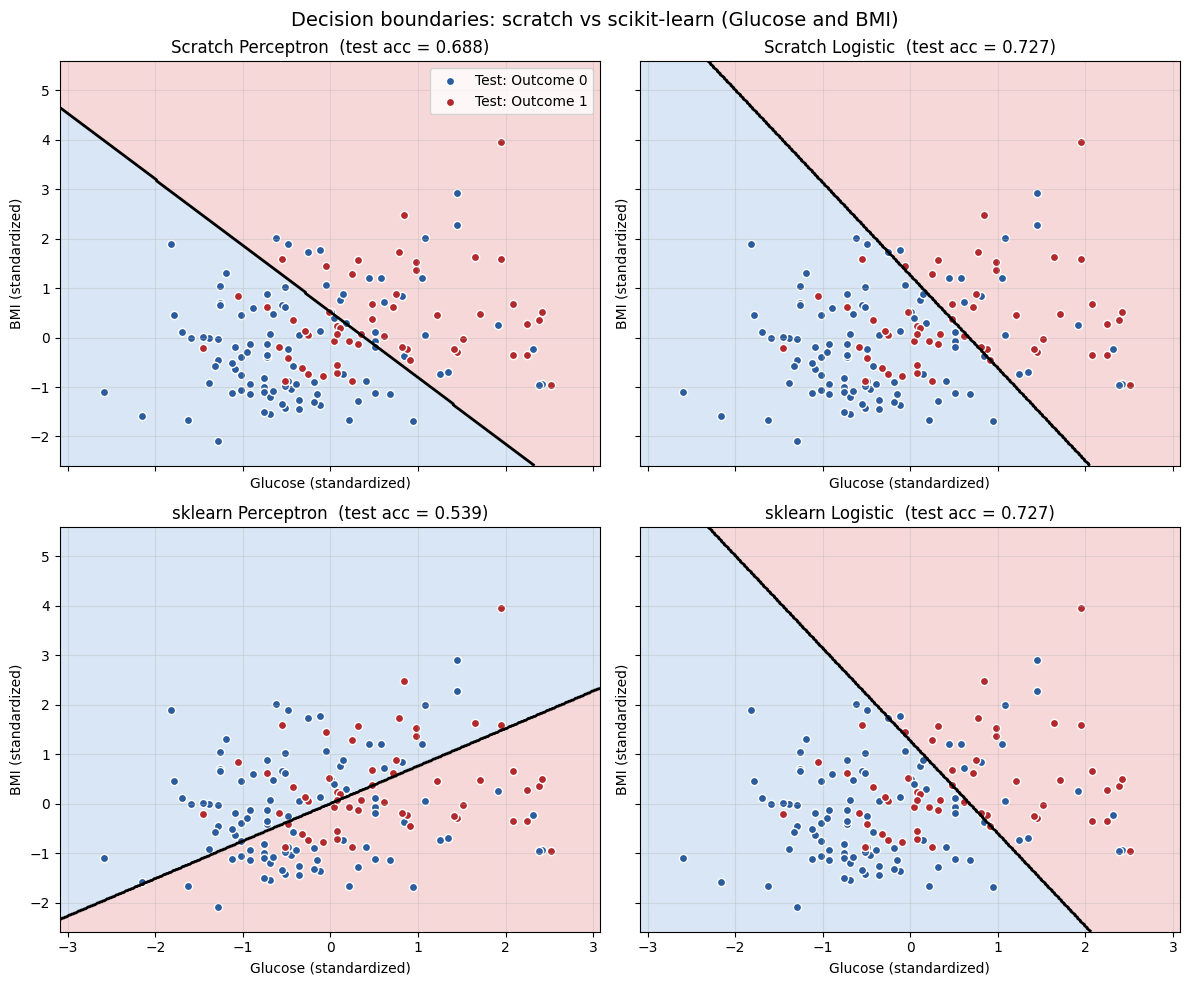

In [7]:
def make_grid(X, pad=0.5, n=400):
    x1 = np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, n)
    x2 = np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, n)
    return np.meshgrid(x1, x2)

X_all = np.vstack([X_train, X_test])
xx, yy = make_grid(X_all)
grid = np.c_[xx.ravel(), yy.ravel()]

predictors = {
    "Scratch Perceptron":  perc_scratch.predict,
    "Scratch Logistic":    logit_scratch.predict,
    "sklearn Perceptron":  perc_sk.predict,
    "sklearn Logistic":    logit_sk.predict,
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)
for ax, (name, pred_fn) in zip(axes.ravel(), predictors.items()):
    zz = pred_fn(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=["#cfe0f3", "#f6cfd0"], alpha=0.8)
    ax.contour(xx, yy, zz, levels=[0.5], colors="k", linewidths=2)
    ax.scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1], c="#2b5c9e", edgecolor="w", s=35, label="Test: Outcome 0")
    ax.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], c="#b22a2e", edgecolor="w", s=35, label="Test: Outcome 1")
    test_acc = (pred_fn(X_test) == y_test).mean()
    ax.set_title(f"{name}  (test acc = {test_acc:.3f})")
    ax.set_xlabel(f"{FEATURES[0]} (standardized)"); ax.set_ylabel(f"{FEATURES[1]} (standardized)")
    ax.grid(alpha=.3)
axes[0, 0].legend(loc="upper right")
plt.suptitle("Decision boundaries: scratch vs scikit-learn (Glucose and BMI)", fontsize=14)
plt.tight_layout(); plt.show()

### 6.1 All four boundaries on one plot

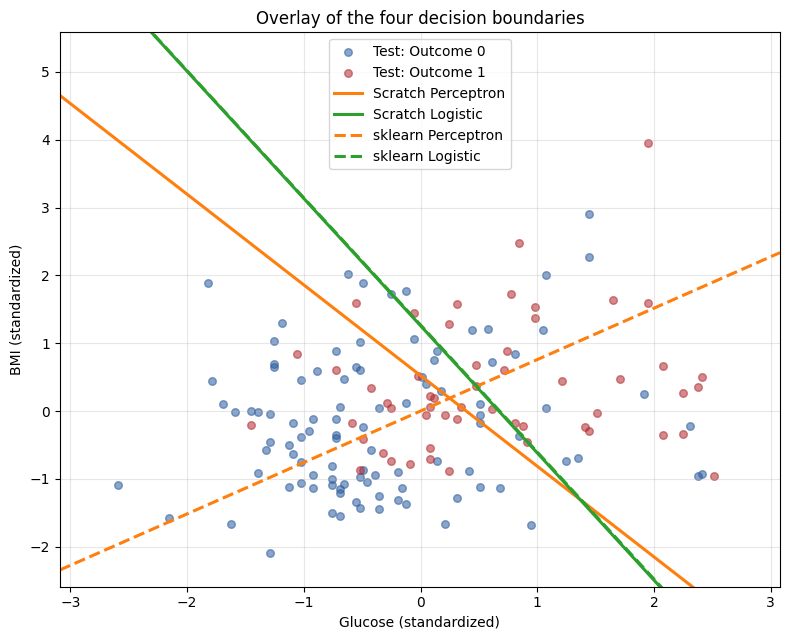

In [8]:
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1], c="#2b5c9e", alpha=.55, s=30, label="Test: Outcome 0")
ax.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], c="#b22a2e", alpha=.55, s=30, label="Test: Outcome 1")

x_line = np.array([X_all[:, 0].min() - 0.5, X_all[:, 0].max() + 0.5])
styles = {"Scratch Perceptron": ("#ff7f0e", "-"), "Scratch Logistic": ("#2ca02c", "-"),
          "sklearn Perceptron": ("#ff7f0e", "--"), "sklearn Logistic": ("#2ca02c", "--")}
for name, (w, b) in models.items():
    y_line = -(w[0] * x_line + b) / w[1]
    c, ls = styles[name]
    ax.plot(x_line, y_line, color=c, ls=ls, lw=2.2, label=name)

ax.set_xlim(x_line); ax.set_ylim(X_all[:, 1].min() - 0.5, X_all[:, 1].max() + 0.5)
ax.set_xlabel(f"{FEATURES[0]} (standardized)"); ax.set_ylabel(f"{FEATURES[1]} (standardized)")
ax.set_title("Overlay of the four decision boundaries")
ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.show()

### 6.2 Logistic regression probability map (extra)

A perceptron only has a hard boundary, while logistic regression gives a **probability** that varies smoothly across the plane. The 0.5 contour is the decision boundary.

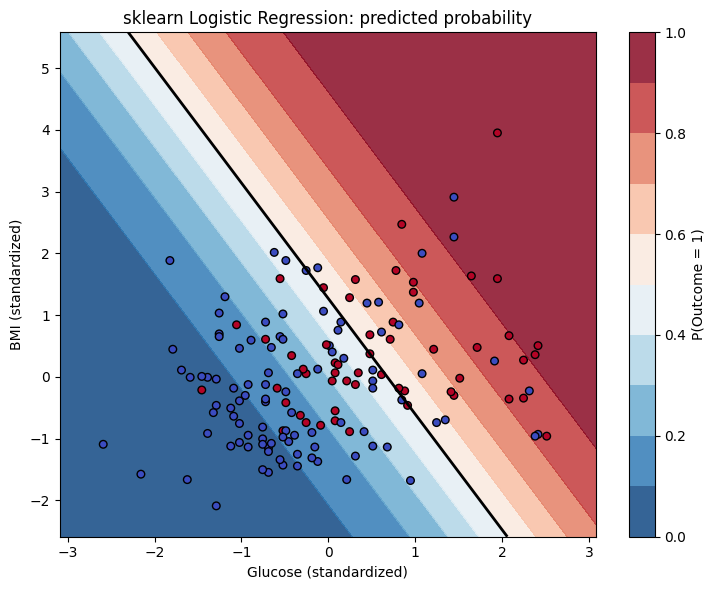

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 6))
proba = logit_sk.predict_proba(grid)[:, 1].reshape(xx.shape)
cs = ax.contourf(xx, yy, proba, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.85)
ax.contour(xx, yy, proba, levels=[0.5], colors="k", linewidths=2)
plt.colorbar(cs, ax=ax, label="P(Outcome = 1)")
ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="coolwarm", edgecolor="k", s=30)
ax.set_xlabel(f"{FEATURES[0]} (standardized)"); ax.set_ylabel(f"{FEATURES[1]} (standardized)")
ax.set_title("sklearn Logistic Regression: predicted probability")
plt.tight_layout(); plt.show()

## 7. How Much Do the Models Actually Disagree?

Differences in the line do not necessarily mean big differences in predictions. We measure the fraction of **test** samples on which each pair of models gives the same label.

In [10]:
test_preds = {name: fn(X_test) for name, fn in predictors.items()}
names = list(test_preds)
agree = pd.DataFrame(
    [[(test_preds[a] == test_preds[b]).mean() for b in names] for a in names],
    index=names, columns=names).round(3)
print("Pairwise agreement of test predictions:")
print(agree.to_string())

print("\nScratch vs sklearn Logistic disagree on",
      int((test_preds["Scratch Logistic"] != test_preds["sklearn Logistic"]).sum()), "of", len(y_test), "test samples")
print("Scratch vs sklearn Perceptron disagree on",
      int((test_preds["Scratch Perceptron"] != test_preds["sklearn Perceptron"]).sum()), "of", len(y_test), "test samples")
print("\nPositive-class prediction rate on test set:")
print(pd.Series({n: p.mean() for n, p in test_preds.items()}).round(3))
print("True positive rate in test set:", round(y_test.mean(), 3))

Pairwise agreement of test predictions:
                    Scratch Perceptron  Scratch Logistic  sklearn Perceptron  sklearn Logistic
Scratch Perceptron               1.000             0.909               0.500             0.909
Scratch Logistic                 0.909             1.000               0.513             1.000
sklearn Perceptron               0.500             0.513               1.000             0.513
sklearn Logistic                 0.909             1.000               0.513             1.000

Scratch vs sklearn Logistic disagree on 0 of 154 test samples
Scratch vs sklearn Perceptron disagree on 77 of 154 test samples

Positive-class prediction rate on test set:
Scratch Perceptron    0.377
Scratch Logistic      0.286
sklearn Perceptron    0.474
sklearn Logistic      0.286
dtype: float64
True positive rate in test set: 0.351


In [11]:
# quick sanity table (full evaluation is Task 4)
sanity = pd.DataFrame({
    "train acc": {n: round(float((fn(X_train) == y_train).mean()), 4) for n, fn in predictors.items()},
    "test acc":  {n: round(float((fn(X_test)  == y_test ).mean()), 4) for n, fn in predictors.items()},
})
sanity

,train acc,test acc
Scratch Perceptron,0.7606,0.6883
Scratch Logistic,0.7785,0.7273
sklearn Perceptron,0.5195,0.5390
sklearn Logistic,0.7801,0.7273


## 8. Robustness of the Perceptron to its Random Seed (extra)

The perceptron's final line depends on the order in which samples are visited, because the data is not separable and the weights keep moving. We refit the sklearn Perceptron with several seeds on the *same* data to see how much the boundary changes, compared with Logistic Regression, which is deterministic.
**Important:** the default `Perceptron` returns its *last* weight vector, and on overlapping classes that last vector can be quite poor (it may even be close to chance for some seeds).

In [12]:
rows = []
for seed in [0, 1, 7, 42, 123]:
    p = Perceptron(max_iter=1000, tol=1e-3, random_state=seed).fit(X_train, y_train)
    w, b = p.coef_[0], p.intercept_[0]
    rows.append({"seed": seed, "n_iter": p.n_iter_,
                 "w1/w2": round(w[0] / w[1], 3),
                 "bias/|w|": round(b / np.linalg.norm(w), 3),
                 "test acc": round(p.score(X_test, y_test), 4),
                 "test positive rate": round(p.predict(X_test).mean(), 3)})
pd.DataFrame(rows).set_index("seed")

,n_iter,w1/w2,bias/|w|,test acc,test positive rate
seed,,,,,
0,12,-8.956,0.000,0.7078,0.448
1,11,1.041,-0.781,0.7013,0.273
7,6,2.362,0.000,0.6883,0.468
42,15,-0.758,0.000,0.5390,0.474
123,13,0.188,0.978,0.3571,0.825


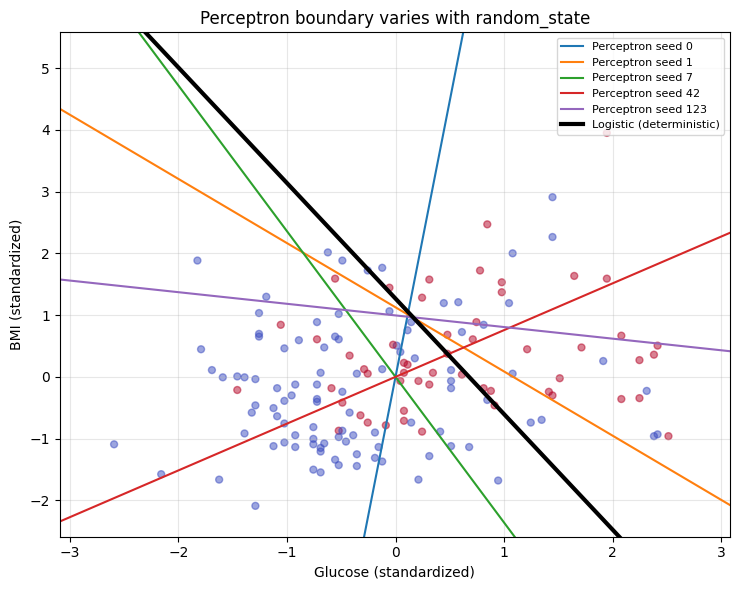

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="coolwarm", s=25, alpha=.5)
for seed in [0, 1, 7, 42, 123]:
    p = Perceptron(max_iter=1000, tol=1e-3, random_state=seed).fit(X_train, y_train)
    w, b = p.coef_[0], p.intercept_[0]
    ax.plot(x_line, -(w[0] * x_line + b) / w[1], lw=1.5, label=f"Perceptron seed {seed}")
w, b = logit_sk.coef_[0], logit_sk.intercept_[0]
ax.plot(x_line, -(w[0] * x_line + b) / w[1], "k-", lw=3, label="Logistic (deterministic)")
ax.set_xlim(x_line); ax.set_ylim(X_all[:, 1].min() - 0.5, X_all[:, 1].max() + 0.5)
ax.set_xlabel(f"{FEATURES[0]} (standardized)"); ax.set_ylabel(f"{FEATURES[1]} (standardized)")
ax.set_title("Perceptron boundary varies with random_state"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 8.1 A more stable perceptron: weight averaging (extra)

A standard remedy is the *averaged perceptron*: return the average of all weight vectors visited during training instead of the last one.
`Perceptron` has no `average` option, but `SGDClassifier(loss="perceptron", penalty=None, learning_rate="constant", eta0=1.0)` is the same algorithm and supports `average=True`.

In [14]:
from sklearn.linear_model import SGDClassifier

rows = []
for seed in [0, 1, 7, 42, 123]:
    ap = SGDClassifier(loss="perceptron", penalty=None, learning_rate="constant", eta0=1.0,
                       average=True, max_iter=1000, tol=1e-3, random_state=seed).fit(X_train, y_train)
    w, b = ap.coef_[0], ap.intercept_[0]
    rows.append({"seed": seed, "w1/w2": round(w[0] / w[1], 3), "bias/|w|": round(b / np.linalg.norm(w), 3),
                 "train acc": round(ap.score(X_train, y_train), 4), "test acc": round(ap.score(X_test, y_test), 4)})
print("Averaged perceptron across seeds (compare with the table above):")
print(pd.DataFrame(rows).set_index("seed").to_string())
print("\nLogistic (sklearn) for reference: w1/w2 = %.3f, bias/|w| = %.3f"
      % (logit_sk.coef_[0][0] / logit_sk.coef_[0][1],
         logit_sk.intercept_[0] / np.linalg.norm(logit_sk.coef_[0])))

Averaged perceptron across seeds (compare with the table above):
      w1/w2  bias/|w|  train acc  test acc
seed                                      
0     1.776    -0.437     0.7834    0.6883
1     1.788    -0.432     0.7834    0.6883
7     1.999    -0.408     0.7801    0.6948
42    1.968    -0.418     0.7818    0.6948
123   1.966    -0.449     0.7818    0.7143

Logistic (sklearn) for reference: w1/w2 = 1.873, bias/|w| = -0.597


## 9. Discussion — How the Boundaries Differ, and Why Coefficients Differ

**Shape.** All four boundaries are straight lines, because both models are *linear* classifiers (a weighted sum thresholded at a fixed value). Neither can bend to follow the overlapping class shape.

**How the lines differ.**
- The two **Logistic Regression** boundaries (scratch and sklearn) are almost the same line: they minimize the same smooth, convex log-loss, so they end at (nearly) the same optimum. The sklearn default is only slightly different because of its L2 shrinkage.
- The two **Perceptron** boundaries do not agree with each other or with the logistic line. On non-separable data the perceptron has no single optimum: it only updates on mistakes, never settles, and the line it returns is simply wherever the last updates left it. With `random_state=42` the sklearn Perceptron stopped after only 15 epochs on a line with a *negative* BMI weight, which behaves close to chance on the test data, while the scratch perceptron (100 epochs, different shuffling) landed on a more sensible line. Section 8 shows this is not a bug but high variance: other seeds give very different lines, and some are much better. It is therefore a **sampling/ordering effect, not evidence that one implementation is superior**.
- The averaged perceptron (Section 8.1) is stable across seeds, with nearly the same direction as the logistic line (w1/w2 about 1.8 to 2.0 vs 1.87) and a somewhat smaller offset, which confirms that the instability comes from using the last iterate, not from the linear model itself.
- Perceptron and logistic lines usually differ in **offset**: the perceptron treats all mistakes equally and ignores how far points are from the line, while logistic regression weights each sample by how wrong its probability is, which makes it balance the class imbalance (≈65 / 35) differently.

**Why exact coefficients differ across implementations.**
1. **Different objective / optimizer.** sklearn's `Perceptron` is an SGD routine with its own learning rate (`eta0=1.0`), update ordering and stopping criterion (`tol`, `n_iter_no_change`, `max_iter`); our scratch version used `lr=0.1`, `max_epochs=100` with its own shuffling.
2. **Regularization.** sklearn's `LogisticRegression` applies L2 regularization by default (`C=1.0`), which shrinks the weights; the scratch version has none. Using `C=1e6` removes most of this effect (Section 4).
3. **Solver and convergence.** sklearn uses `lbfgs`, our scratch code uses plain batch gradient descent with a tolerance; they stop at slightly different points near the optimum.
4. **Early stopping on a noisy loss.** sklearn's `Perceptron` stops when the loss fails to improve by `tol` for 5 epochs. On overlapping classes the loss fluctuates, so the stopping epoch (and hence the returned weights) is quite arbitrary.
5. **Scale of the perceptron coefficients is arbitrary.** Multiplying `(w, b)` by any positive constant leaves a step-function classifier unchanged, so only the **ratio** and the offset are meaningful, not the absolute values.
6. **Randomness.** Shuffling depends on `random_state` and on the random-number generator used (NumPy `default_rng` in scratch vs. sklearn's internal generator), so even the same seed number gives different visiting orders.

Therefore, we should compare the models through their **boundaries and predictions** rather than through raw coefficient values.

## 10. Save Results for Task 4

In [15]:
np.savez("library_models_results.npz",
         perc_sk_coef=perc_sk.coef_[0], perc_sk_intercept=perc_sk.intercept_[0],
         perc_sk_test_pred=perc_sk.predict(X_test),
         logit_sk_coef=logit_sk.coef_[0], logit_sk_intercept=logit_sk.intercept_[0],
         logit_sk_test_pred=logit_sk.predict(X_test),
         logit_sk_test_proba=logit_sk.predict_proba(X_test)[:, 1])
print("Saved library_models_results.npz")

Saved library_models_results.npz


## Summary of Task 3

| Item | Choice |
|---|---|
| Data | Identical prepared train/test arrays from Task 1 (no re-splitting, no re-scaling) |
| Library models | `Perceptron(max_iter=1000, tol=1e-3, random_state=42)`, `LogisticRegression(random_state=42)` |
| Plots | 2×2 decision-region grid for all four models, one overlay of the four lines, a logistic probability map, and a perceptron seed-sensitivity plot |
| Main finding | The logistic boundaries agree closely (0 of 154 test predictions differ); the sklearn Perceptron boundary is highly seed-dependent and, for seed 42, poor; averaging the weights stabilizes it; coefficients differ because of regularization, optimizer, learning rate, stopping rule and shuffling |
| Next | Task 4: confusion matrix, accuracy, precision, recall and F1 for all four models, with a manual metric implementation |